# NOAA + GEBCO + GPW4 — bacias hidrográficas, população e microplásticos
## América do Norte até o Canal do Panamá

Pergunta: a população de uma bacia de drenagem explica o microplástico (pellets do Nurdle Patrol, NOAA)
encontrado na sua foz? A unidade de análise é a **bacia**: população, manchas urbanas e lixo são
agregados por bacia, e a lei de escala (alometria) população × lixo é ajustada entre bacias.

## 1. Setup

In [1]:
import glob, json, os, subprocess, sys, zipfile

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rioxarray", "powerlaw"], check=True)

def local(caminho):
    """Procura o arquivo na pasta do notebook e, fora do Colab, na raiz do repositório e em dados/."""
    for base in (".", "..", "dados", os.path.join("..", "dados")):
        p = os.path.join(base, caminho)
        if os.path.exists(p):
            return p
    return None


def baixa_zip(id_drive, zip_destino, pasta):
    if local(pasta) is None:
        import gdown
        gdown.download(id=id_drive, output=zip_destino, quiet=True)
        zipfile.ZipFile(zip_destino).extractall(pasta)
    return local(pasta)


def baixa_arquivo(id_drive, destino):
    if local(destino) is None:
        import gdown
        gdown.download(id=id_drive, output=destino, quiet=True)
    return local(destino)


def clona(url, pasta):
    if not os.path.isdir(pasta):
        subprocess.run(["git", "clone", "-q", "--depth", "1", url, pasta], check=True)

GPW_DIR = baixa_zip("1c7nym3mWXzcy7iy_j1MQmCs4-RCZG0kO", "gpw_data.zip", "gpw_data")
NOAA_CSV = baixa_arquivo("1YssUUZS6CAQUXBjGOp1Aw-j8XwVeoP_y", "noaa_microplastics.csv")
clona("https://github.com/erneson/IPBA.git", "IPBA")
clona("https://github.com/skaduhs5232/CCA.git", "CCA")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window
import powerlaw
from scipy import ndimage as ndi
from scipy.stats import pearsonr, spearmanr
sys.path.insert(0, "CCA")
from cca import cca_grid

os.makedirs("results", exist_ok=True)

### Estilo das figuras

Padrão único para todas as figuras: fonte serifada de 8–9 pt, largura de 3,6 in (uma coluna) ou 7,2 in (duas colunas), paleta Okabe–Ito (segura para daltonismo), mapas com razão de aspecto geográfica ($1/\cos\varphi$), coordenadas em graus e barra de escala. Cada figura é salva em `results/` como PDF (vetorial, para o LaTeX) e PNG de 300 dpi. Os títulos ficam para a legenda do artigo; no gráfico vão só letras de painel.

In [2]:
from matplotlib.colors import ListedColormap, LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Ellipse, Rectangle, ConnectionPatch
import matplotlib.patheffects as pe
from matplotlib.ticker import FuncFormatter, MaxNLocator

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "mathtext.fontset": "dejavuserif",
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 8.5, "legend.fontsize": 7,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.linewidth": 0.7,
    "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 1.2, "image.interpolation": "nearest", "pdf.fonttype": 42,
})
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
RELEVO = ListedColormap(plt.cm.terrain(np.linspace(0.25, 1.0, 256)))
COR_MANCHA = "#5E3C99"
COR_OCEANO, COR_TERRA = "#dce8f2", "0.86"
MUNDO = (-180.0, -90.0, 180.0, 90.0)
MUNDO_EXT = (MUNDO[0], MUNDO[2], MUNDO[1], MUNDO[3])   # ordem do imshow
# o GPW (30") tem ~4x mais pixels por lado do que cabem num painel: as camadas raster dele são
# desenhadas em blocos FATOR_VIS x FATOR_VIS (soma para população, máximo para as manchas)
FATOR_VIS = 6


def extensao(da):
    x, y = da.x.values, da.y.values
    dx, dy = abs(x[1] - x[0]), abs(y[1] - y[0])
    return (x.min() - dx / 2, x.max() + dx / 2, y.min() - dy / 2, y.max() + dy / 2)


def _grau(v, pos, neg):
    s = f"{abs(v):.1f}".rstrip("0").rstrip(".")
    return f"{s}°{neg if v < 0 else pos}"


def eixos_geo(ax, box=None):
    if box is not None:
        ax.set_xlim(box[0], box[2])
        ax.set_ylim(box[1], box[3])
    ax.set_aspect(1.0 / np.cos(np.radians(np.mean(ax.get_ylim()))))
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: _grau(v, "L", "O")))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: _grau(v, "N", "S")))
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(True)


def blocos(a, f, func=np.sum):
    """Agrega a em blocos f x f (sobras das bordas descartadas)."""
    h, w = (a.shape[0] // f) * f, (a.shape[1] // f) * f
    return func(a[:h, :w].reshape(h // f, f, w // f, f), axis=(1, 3))


def extensao_blocos(da, f):
    x0, x1, y0, y1 = extensao(da)
    px, py = (x1 - x0) / da.sizes["x"], (y1 - y0) / da.sizes["y"]
    return (x0, x0 + (da.sizes["x"] // f) * f * px, y1 - (da.sizes["y"] // f) * f * py, y1)


def liga_zoom(fig, ax_mundo, ax_zoom, box):
    """Retângulo do recorte no mapa-múndi e linhas até os cantos do painel ampliado."""
    x0, y0, x1, y1 = box
    ax_mundo.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="k", lw=1.0, zorder=10))
    for xy_mundo, xy_zoom in (((x0, y0), (0, 1)), ((x1, y0), (1, 1))):
        fig.add_artist(ConnectionPatch(xyA=xy_mundo, coordsA=ax_mundo.transData, xyB=xy_zoom,
                                       coordsB=ax_zoom.transAxes, color="0.35", lw=0.7, ls="--"))


def eixos_mundo(ax):
    ax.set_facecolor(COR_OCEANO)
    eixos_geo(ax, MUNDO)
    ax.set_xticks([-120, -60, 0, 60, 120])
    ax.set_yticks([-60, -30, 0, 30, 60])
    ax.tick_params(labelsize=6)


def barra_escala(ax, km, pos=(0.05, 0.05)):
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    dlon = km / (111.32 * np.cos(np.radians((y0 + y1) / 2)))
    xa, ya = x0 + pos[0] * (x1 - x0), y0 + pos[1] * (y1 - y0)
    ax.plot([xa, xa + dlon], [ya, ya], c="k", lw=2.2, solid_capstyle="butt", zorder=10)
    ax.text(xa + dlon / 2, ya + 0.015 * (y1 - y0), f"{km} km", ha="center", va="bottom",
            fontsize=6.5, zorder=10)


def letra(ax, s):
    ax.text(0.0, 1.015, f"({s})", transform=ax.transAxes, fontweight="bold", ha="left", va="bottom")


def salva(fig, nome, dpi=None):
    fig.savefig(f"results/{nome}.pdf")
    fig.savefig(f"results/{nome}.png", dpi=dpi or plt.rcParams["savefig.dpi"])


def relevo_vis(f=2):
    """Relevo do recorte em blocos f x f (máximo) com o oceano mascarado, só para exibição."""
    z = blocos(np.where(sea, -np.inf, dem.values), f, np.max)
    return np.where(np.isfinite(z), z, np.nan), extensao_blocos(dem, f)


def fmt_br(x, casas=0):
    return f"{x:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def _inclinacao(X, Y):
    Xc = X - X.mean(axis=-1, keepdims=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (Xc * (Y - Y.mean(axis=-1, keepdims=True))).sum(-1) / (Xc ** 2).sum(-1)


def ajuste_escala(x, y, n_boot=10_000, semente=0):
    """Lei de escala y = c x^beta por MQO em log10, IC 95% por bootstrap de pares e p de permutação (beta = 0)."""
    lx, ly = np.log10(x), np.log10(y)
    n = len(lx)
    beta = float(_inclinacao(lx, ly))
    a = float(ly.mean() - beta * lx.mean())
    rng = np.random.default_rng(semente)
    i = rng.integers(0, n, (n_boot, n))
    bb = _inclinacao(lx[i], ly[i])
    aa = ly[i].mean(-1) - bb * lx[i].mean(-1)
    ok = np.isfinite(bb)
    perm = _inclinacao(np.broadcast_to(lx, (n_boot, n)), rng.permuted(np.tile(ly, (n_boot, 1)), axis=1))
    xs = np.linspace(lx.min(), lx.max(), 100)
    banda = np.percentile(aa[ok, None] + bb[ok, None] * xs[None, :], [2.5, 97.5], axis=0)
    r, p_r = pearsonr(lx, ly)
    rho, p_rho = spearmanr(lx, ly)
    return dict(n=n, beta=beta, log10_c=a, ic95_inf=float(np.percentile(bb[ok], 2.5)),
                ic95_sup=float(np.percentile(bb[ok], 97.5)),
                p_perm=float((np.sum(np.abs(perm) >= abs(beta)) + 1) / (n_boot + 1)),
                r=float(r), p_r=float(p_r), rho=float(rho), p_rho=float(p_rho), r2=float(r ** 2),
                xs=xs, ys=a + beta * xs, banda=banda)


def texto_ajuste(f):
    return (f"$\\beta = {f['beta']:.2f}$  [{f['ic95_inf']:.2f}, {f['ic95_sup']:.2f}]\n"
            f"$r = {f['r']:.2f}$,  $\\rho_s = {f['rho']:.2f}$\n"
            f"$p_\\mathrm{{perm}} = {f['p_perm']:.3f}$,  $n = {f['n']}$")

## 2. Recorte da região

EUA contíguo, sul do Canadá até 50°N, México, América Central e Caribe, cortando no Canal do Panamá: a
leste de 79°W e ao sul de 12,6°N a caixa pega a América do Sul, que vira oceano no relevo e tem a
população zerada. Com o recorte continental, bacias como a do Mississippi e a do Rio Grande entram
inteiras, em vez de cortadas pela caixa do Texas.

**Resolução do relevo.** O IPBA cria um objeto Python por pixel e grava os rótulos das bacias em
`uint16` (no máximo 65.535 sinks). O GEBCO nativo (15″) daria ~150 milhões de pixels nesta caixa, então
ele é reamostrado pela média em blocos de `FATOR_GEBCO` × `FATOR_GEBCO` pixels (8 → 2′, ~3,7 km).
O GPW continua em 30″.

**Oceano.** É oceano todo pixel com elevação ≤ 0 conectado à borda do recorte. Depressões interiores
abaixo do nível do mar (Salton Sea, Death Valley, fundo dos Grandes Lagos no GEBCO) continuam sendo
terra: não são foz de rio e não viram sinks.

> `rioxarray`: `.where()` descarta o CRS do raster, por isso o `write_crs` explícito antes de cada `to_raster`.

In [3]:
minx, miny, maxx, maxy = -125.0, 7.0, -65.0, 50.0
BOX = (minx, miny, maxx, maxy)
# Corte no Canal do Panamá: ao sul de 12,6°N e a leste de 79°W é América do Sul (costa da Colômbia e
# da Venezuela, ilhas ABC). 79°W fica logo a leste do canal, para não partir a mancha da Cidade do Panamá.
CANAL_LON, CANAL_LAT = -79.0, 12.6
TAG = "na_panama"


def mascara_sul(da):
    """True nos pixels da América do Sul (a leste do canal), que ficam fora da análise."""
    return (da.y.values[:, None] < CANAL_LAT) & (da.x.values[None, :] > CANAL_LON)
ESCALA_KM = 500
FATOR_GEBCO = 8                      # 15" -> 2'

URL_GEBCO = "https://data.source.coop/alexgleith/gebco-2024/GEBCO_2024.tif"
gebco = rioxarray.open_rasterio(URL_GEBCO, chunks=True)
dem = (gebco.rio.clip_box(minx=minx, miny=miny, maxx=maxx, maxy=maxy).squeeze()
       .coarsen(x=FATOR_GEBCO, y=FATOR_GEBCO, boundary="trim").mean().astype("float32").load())
dem.rio.write_crs("EPSG:4326", inplace=True)
dem.rio.write_transform(dem.rio.transform(recalc=True), inplace=True)
sul_g = mascara_sul(dem)
dem = dem.copy(data=np.where(sul_g, -1.0, dem.values).astype("float32"))

abaixo, _ = ndi.label(dem.values <= 0)
ids_borda = np.unique(np.concatenate([abaixo[0], abaixo[-1], abaixo[:, 0], abaixo[:, -1]]))
sea = np.isin(abaixo, ids_borda[ids_borda > 0])
print(f"GEBCO reamostrado: {dem.shape[0]} x {dem.shape[1]} pixels de {abs(dem.rio.resolution()[0]) * 60:.1f}′ | "
      f"{int(((dem.values <= 0) & ~sea).sum())} pixels abaixo de 0 m no interior ficam como terra")
dem.copy(data=np.where(sea, -9999.0, dem.values).astype("float32")).rio.write_crs("EPSG:4326") \
   .rio.write_nodata(-9999).rio.to_raster("IPBA/datasets/relevo.tif", dtype="float32")

# GPW v4: recorte da população
gpw = rioxarray.open_rasterio(glob.glob(os.path.join(GPW_DIR, "*.tif"))[0]).squeeze()
pop = gpw.rio.clip_box(minx=minx, miny=miny, maxx=maxx, maxy=maxy)
pop = pop.where(pop > 0, 0.0)
pop = pop.copy(data=np.where(mascara_sul(pop), 0.0, pop.values))
pop.rio.write_crs("EPSG:4326", inplace=True)

RasterioIOError: HTTP response code: 404

### recorte no mapa-múndi

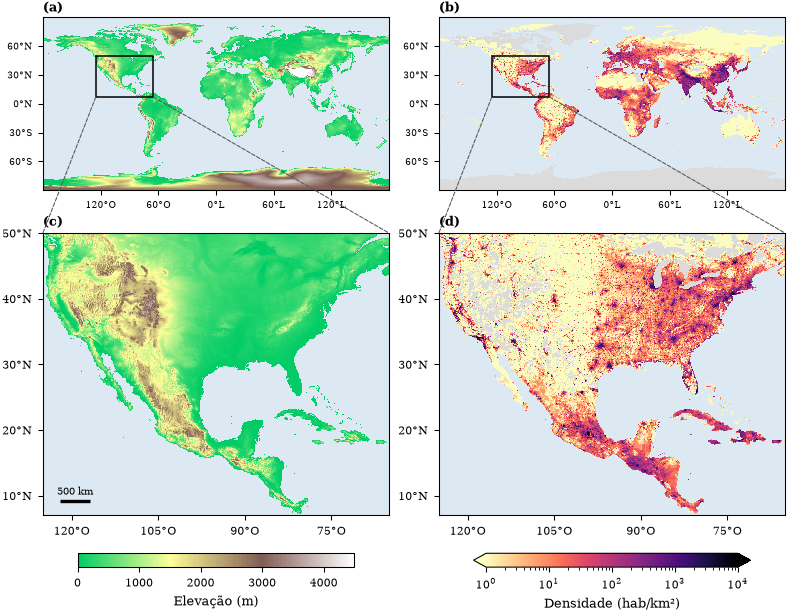

In [ ]:
with rasterio.open(URL_GEBCO) as src:      # o COG tem overviews: a leitura reduzida baixa só a overview
    gebco_mundo = src.read(1, out_shape=(src.height // 80, src.width // 80),
                           resampling=Resampling.average).astype("float32")
    ext_gebco = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)


def gpw_mundo(caminho, f=40):
    """GPW somado em blocos f x f, lido em faixas de linhas (o GeoTIFF não tem overviews)."""
    cache = os.path.join("results", f"gpw_mundo_{f}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        return z["pop"], tuple(z["ext"])
    with rasterio.open(caminho) as src:
        h, w = src.height // f, src.width // f
        soma_pop = np.zeros((h, w))
        faixa = 12 * f
        for r0 in range(0, h * f, faixa):
            n = min(faixa, h * f - r0)
            a = src.read(1, window=Window(0, r0, w * f, n)).astype("float64")
            a[~np.isfinite(a) | (a < 0)] = 0.0
            soma_pop[r0 // f:(r0 + n) // f] = a.reshape(n // f, f, w, f).sum(axis=(1, 3))
        ext = (src.bounds.left, src.bounds.left + w * f * src.res[0], src.bounds.top - h * f * src.res[1], src.bounds.top)
    np.savez(cache, pop=soma_pop, ext=ext)
    return soma_pop, ext


F_MUNDO = 40
pop_mundo, ext_gpw = gpw_mundo(glob.glob(os.path.join(GPW_DIR, "*.tif"))[0], F_MUNDO)
lat_b = ext_gpw[3] - (np.arange(pop_mundo.shape[0]) + 0.5) * (ext_gpw[3] - ext_gpw[2]) / pop_mundo.shape[0]
res_b = (ext_gpw[1] - ext_gpw[0]) / pop_mundo.shape[1]
dens_mundo = pop_mundo / (((res_b * 111.32) ** 2) * np.cos(np.radians(lat_b)))[:, None]

res_p = np.abs(pop.rio.resolution())
area_gpw = ((res_p[0] * 111.32) * np.cos(np.radians(pop.y.values)))[:, None] * (res_p[1] * 111.32)
pop_rec = np.nan_to_num(pop.values, nan=0.0)
dens_rec = blocos(pop_rec, FATOR_VIS) / blocos(np.broadcast_to(area_gpw, pop_rec.shape), FATOR_VIS)
ext_rec = extensao_blocos(pop, FATOR_VIS)

norma_relevo = Normalize(0, 4500)
norma_dens = LogNorm(1, 1e4)
fig = plt.figure(figsize=(7.2, 5.6), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.55])
ax_m = [fig.add_subplot(gs[0, k]) for k in range(2)]
ax_z = [fig.add_subplot(gs[1, k]) for k in range(2)]

eixos_mundo(ax_m[0])
ax_m[0].imshow(np.where(gebco_mundo > 0, gebco_mundo, np.nan), extent=ext_gebco, cmap=RELEVO, norm=norma_relevo)
ax_z[0].set_facecolor(COR_OCEANO)
z_vis, ext_vis = relevo_vis()
im = ax_z[0].imshow(z_vis, extent=ext_vis, cmap=RELEVO, norm=norma_relevo)
fig.colorbar(im, ax=ax_z[0], location="bottom", shrink=0.8, label="Elevação (m)")

eixos_mundo(ax_m[1])
ax_m[1].imshow(np.where(gebco_mundo > 0, 1.0, np.nan), extent=ext_gebco, cmap=ListedColormap([COR_TERRA]))
ax_m[1].imshow(np.where(dens_mundo > 0, dens_mundo, np.nan), extent=ext_gpw, cmap="magma_r", norm=norma_dens)
ax_z[1].set_facecolor(COR_OCEANO)
ax_z[1].imshow(np.where(sea, np.nan, 1.0), extent=extensao(dem), cmap=ListedColormap([COR_TERRA]))
im = ax_z[1].imshow(np.where(dens_rec > 0, dens_rec, np.nan), extent=ext_rec, cmap="magma_r", norm=norma_dens)
fig.colorbar(im, ax=ax_z[1], location="bottom", shrink=0.8, label="Densidade (hab/km²)", extend="both")

for k in range(2):
    eixos_geo(ax_z[k], BOX)
    liga_zoom(fig, ax_m[k], ax_z[k], BOX)
for ax, l in zip(ax_m + ax_z, "abcd"):
    letra(ax, l)
barra_escala(ax_z[0], ESCALA_KM)
salva(fig, f"recorte_{TAG}", dpi=200)
plt.show()

### Microplásticos (NOAA) no mundo e no recorte

Em cima, o banco NOAA inteiro numa grade de 2° (baixa resolução, como os rasters acima): em cor, a mediana
das amostras do Nurdle Patrol (*pieces/10 mins*) em cada célula; em cinza, células que só têm amostras de
outros métodos (redes de arrasto em *pieces/m³*, sedimento em *pieces/kg*), que não entram na análise porque
as unidades não se comparam. Embaixo, cada site do Nurdle Patrol no recorte, com a média das suas amostras;
contagens zero ficam como círculos vazios.

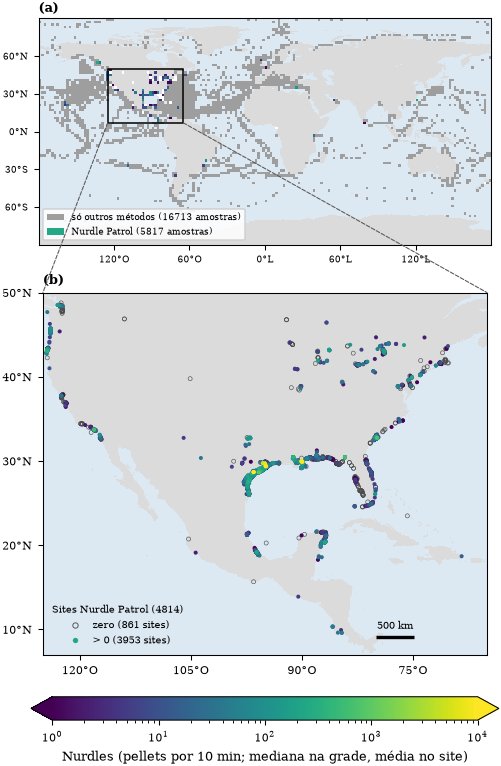

In [ ]:
noaa_bruto = pd.read_csv(NOAA_CSV, low_memory=False)
e_nurdle = noaa_bruto["Unit"].eq("pieces/10 mins") & noaa_bruto["Standardized Nurdle  Amount"].notna()
lon_b, lat_b_noaa = noaa_bruto["Longitude (degree)"], noaa_bruto["Latitude (degree)"]
RES_NOAA = 2.0
col_b = np.clip(((lon_b + 180) // RES_NOAA).astype(int), 0, int(360 / RES_NOAA) - 1)
lin_b = np.clip(((90 - lat_b_noaa) // RES_NOAA).astype(int), 0, int(180 / RES_NOAA) - 1)
grade_outros = np.zeros((int(180 / RES_NOAA), int(360 / RES_NOAA)), dtype=bool)
grade_outros[lin_b[~e_nurdle], col_b[~e_nurdle]] = True
med = noaa_bruto[e_nurdle].groupby([lin_b[e_nurdle], col_b[e_nurdle]])["Standardized Nurdle  Amount"].median()
grade_nurdle = np.full(grade_outros.shape, np.nan)
grade_nurdle[med.index.get_level_values(0), med.index.get_level_values(1)] = med.to_numpy()

no_rec = (e_nurdle & lon_b.between(minx, maxx) & lat_b_noaa.between(miny, maxy)
          & ~((lat_b_noaa < CANAL_LAT) & (lon_b > CANAL_LON)))
site_rec = (noaa_bruto[no_rec].groupby(["Longitude (degree)", "Latitude (degree)"])["Standardized Nurdle  Amount"]
            .mean().rename("conc").reset_index().sort_values("conc"))
zero = site_rec["conc"].eq(0)

norma_conc = LogNorm(1, 1e4)
CMAP_CONC = "viridis"
fig = plt.figure(figsize=(5.4, 7.0), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.6])
ax_m, ax_z = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

eixos_mundo(ax_m)
ax_m.imshow(np.where(gebco_mundo > 0, 1.0, np.nan), extent=ext_gebco, cmap=ListedColormap([COR_TERRA]))
ax_m.imshow(np.where(grade_outros & np.isnan(grade_nurdle), 1.0, np.nan), extent=MUNDO_EXT,
            cmap=ListedColormap(["0.62"]))
ax_m.imshow(np.where(grade_nurdle > 0, grade_nurdle, np.nan), extent=MUNDO_EXT, cmap=CMAP_CONC, norm=norma_conc)
ax_m.imshow(np.where(grade_nurdle == 0, 1.0, np.nan), extent=MUNDO_EXT, cmap=ListedColormap(["w"]))
ax_m.legend(handles=[Patch(fc="0.62", label=f"só outros métodos ({int((~e_nurdle).sum())} amostras)"),
                     Patch(fc=plt.get_cmap(CMAP_CONC)(0.6), label=f"Nurdle Patrol ({int(e_nurdle.sum())} amostras)")],
            loc="lower left", fontsize=5.8, frameon=True, framealpha=0.85)

ax_z.set_facecolor(COR_OCEANO)
z_vis, ext_vis = relevo_vis()
ax_z.imshow(np.where(np.isnan(z_vis), np.nan, 1.0), extent=ext_vis, cmap=ListedColormap([COR_TERRA]))
ax_z.scatter(site_rec.loc[zero, "Longitude (degree)"], site_rec.loc[zero, "Latitude (degree)"], s=7,
             facecolors="none", edgecolors="0.3", linewidths=0.4, rasterized=True,
             label=f"zero ({int(zero.sum())} sites)")
sc = ax_z.scatter(site_rec.loc[~zero, "Longitude (degree)"], site_rec.loc[~zero, "Latitude (degree)"], s=7,
                  c=site_rec.loc[~zero, "conc"], cmap=CMAP_CONC, norm=norma_conc, lw=0, rasterized=True,
                  label=f"> 0 ({int((~zero).sum())} sites)")
ax_z.legend(handles=[Line2D([], [], ls="", marker="o", ms=3.5, mfc="none", mec="0.3", mew=0.6,
                           label=f"zero ({int(zero.sum())} sites)"),
                    Line2D([], [], ls="", marker="o", ms=3.5, mfc=plt.get_cmap(CMAP_CONC)(0.6), mec="none",
                           label=f"> 0 ({int((~zero).sum())} sites)")],
            loc="lower left", fontsize=6.5, title=f"Sites Nurdle Patrol ({len(site_rec)})", title_fontsize=6.5)
fig.colorbar(sc, ax=ax_z, location="bottom", shrink=0.8, extend="both",
             label="Nurdles (pellets por 10 min; mediana na grade, média no site)")
eixos_geo(ax_z, BOX)
liga_zoom(fig, ax_m, ax_z, BOX)
letra(ax_m, "a")
letra(ax_z, "b")
barra_escala(ax_z, ESCALA_KM, pos=(0.75, 0.05))
salva(fig, f"pontos_coleta_{TAG}", dpi=200)
plt.show()

## 3. Bacias hidrográficas: sinks costeiros + IPBA

In [ ]:
# Sinks: cada pixel de terra 4-vizinho do oceano é um sink individual
viz4 = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool)
coastal = ~sea & ndi.binary_dilation(sea, structure=viz4)

n_sinks = int(coastal.sum())
assert n_sinks < 65535, f"{n_sinks} sinks: o IPBA grava os rótulos em uint16; aumente FATOR_GEBCO"
sinks = np.zeros(dem.shape, dtype="uint16")
sinks[coastal] = np.arange(1, n_sinks + 1)
dem.copy(data=sinks).rio.write_crs("EPSG:4326").rio.write_nodata(0) \
   .rio.to_raster("IPBA/datasets/sinks.tif", dtype="uint16")
print(f"{n_sinks} sinks costeiros; IPBA em {dem.size:,} pixels (em Python puro: pode levar dezenas de minutos)")

# IPBA (o mesmo interpretador do kernel, para usar o GDAL do ambiente)
subprocess.run([sys.executable, "-B", "main.py", "relevo", "sinks", "42", "F"], cwd="IPBA", check=True)

bacia = rioxarray.open_rasterio("IPBA/results/relevo.tif").squeeze().load()
bacia.rio.write_crs("EPSG:4326", inplace=True)
assert bacia.shape == dem.shape

11851 sinks costeiros; IPBA em 2,322,000 pixels (em Python puro: pode levar dezenas de minutos)


## 4. Bacias principais ($P = 0{,}90$)

138 bacias cobrem 90.0% da área de terra (11851 bacias no total)
6 bacias principais tocam a borda do recorte (área e população truncadas)


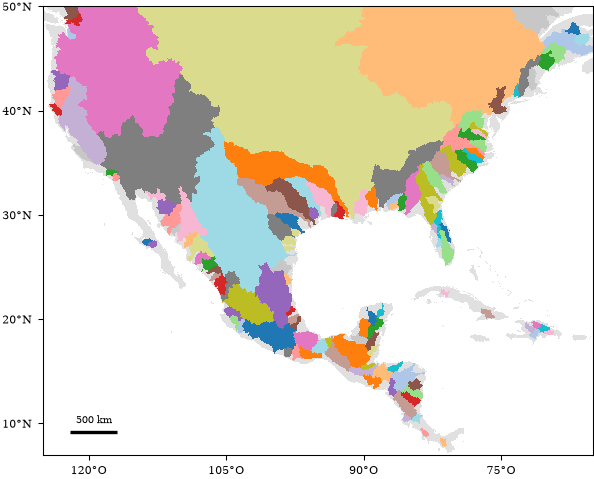

In [ ]:
ids, counts = np.unique(bacia.values[bacia.values > 0], return_counts=True)
dxg, dyg = np.abs(dem.rio.resolution())
area_gebco = np.broadcast_to(((dxg * 111.32) * np.cos(np.radians(dem.y.values)))[:, None] * (dyg * 111.32),
                             dem.shape)
# truncadas: bacias na borda da caixa ou encostadas no corte do Canal do Panamá
corte = ndi.binary_dilation(sul_g, structure=viz4) & ~sul_g
bordas = np.concatenate([bacia.values[0], bacia.values[-1], bacia.values[:, 0], bacia.values[:, -1],
                         bacia.values[corte]])

df_areas = pd.DataFrame({"basin_id": ids, "area_px": counts,
                         "area_km2": ndi.sum(area_gebco, bacia.values, index=ids),
                         "toca_borda": np.isin(ids, bordas)}).sort_values("area_km2", ascending=False)
df_areas["frac_acum"] = df_areas["area_km2"].cumsum() / df_areas["area_km2"].sum()
# a bacia que cruza P entra no conjunto; com "frac_acum <= P" a cobertura ficaria abaixo de P
major = df_areas.loc[df_areas["frac_acum"].shift(fill_value=0.0) < 0.90, "basin_id"].to_numpy()
princ = df_areas[df_areas["basin_id"].isin(major)]
print(f"{len(major)} bacias cobrem {princ['area_km2'].sum() / df_areas['area_km2'].sum():.1%} da área de terra "
      f"({len(ids)} bacias no total)")
print(f"{int(princ['toca_borda'].sum())} bacias principais tocam a borda do recorte (área e população truncadas)")

lut = np.full(int(bacia.values.max()) + 1, np.nan)
lut[major] = np.random.default_rng(0).permutation(len(major)) % 20


def camada_bacias(ax, alpha=1.0):
    ax.imshow(lut[bacia.values], extent=extensao(bacia), cmap="tab20", vmin=-0.5, vmax=19.5, alpha=alpha)


fig, ax = plt.subplots(figsize=(7.2, 4.4), constrained_layout=True)
ax.imshow(np.where(~sea, 1.0, np.nan), extent=extensao(dem), cmap=ListedColormap(["0.88"]))
camada_bacias(ax)
eixos_geo(ax, BOX)
barra_escala(ax, ESCALA_KM)
salva(fig, f"bacias_principais_{TAG}")
plt.show()

## 5. Manchas urbanas: CCA com $(D^*, \ell)$ calibrados pela lei de Zipf

$D^*$ e $\ell$ vêm do `01_Zipf_calibracao_CCA.ipynb`: entre os pares da grade $D^* = 10, \dots, 3000$ hab/km²
× $\ell = 100, \dots, 5000$ m, o escolhido é o que faz as manchas do recorte seguirem a lei de Zipf
($\alpha = 1$). Aquele notebook grava `results/cca_calibracao.json`; no Colab, envie o arquivo para a pasta
`results/` deste notebook antes de rodar esta célula.

O CCA vem do repositório [skaduhs5232/CCA](https://github.com/skaduhs5232/CCA) (`cca_grid`): cada pixel do
GPW é um sítio no seu centro, ativado se a densidade supera $D^*$; dois pixels ativados ficam na mesma
mancha se estão ligados por uma cadeia de pixels ativados a menos de $\ell$ (distância haversine) um do outro.

In [ ]:
CALIB = local(os.path.join("results", "cca_calibracao.json"))
if CALIB:
    with open(CALIB, encoding="utf-8") as f:
        cal = json.load(f)
    D_star, l_metros = cal["D_star"], cal["l_metros"]
    print(f"calibração pela lei de Zipf ({CALIB}): D* = {D_star} hab/km², l = {l_metros} m, alpha(N) = "
          + ", ".join(f"{a:.3f}" for a in cal["alpha_hill"].values()))
else:
    D_star, l_metros = 386, 3000
    print("ATENÇÃO: results/cca_calibracao.json não encontrado. Rode o 01_Zipf_calibracao_CCA.ipynb; até lá, "
          "usando provisoriamente o limiar urbano do U.S. Census (386 hab/km², l = 3 km).")

dx, dy = np.abs(pop.rio.resolution())
# a área do pixel varia com a latitude: dx em graus rende menos km longe do equador (fator cos)
area_px_km2 = ((dx * 111.32) * np.cos(np.radians(pop.y.values)))[:, None] * (dy * 111.32)

dens = np.nan_to_num(pop.values, nan=0.0)
cidades, pop_cidades, area_cidades = cca_grid(dens, pop.x.values, pop.y.values, area_px_km2,
                                              D_star, l_metros / 1000)   # 0 = nao urbano, k = mancha k
n_cidades = len(pop_cidades)

print(f"{n_cidades} manchas urbanas (CCA) | maior: {pop_cidades.max():,.0f} hab | "
      f"{pop_cidades.sum() / dens.sum():.0%} da população do recorte é urbana")


def camada_manchas(ax, cor=COR_MANCHA, **kw):
    # máximo em blocos: uma mancha de 1 pixel do GPW continua visível na escala continental
    m = blocos(cidades > 0, FATOR_VIS, np.any)
    ax.imshow(np.where(m, 1.0, np.nan), extent=extensao_blocos(pop, FATOR_VIS), cmap=ListedColormap([cor]), **kw)

calibração pela lei de Zipf (.\results\cca_calibracao.json): D* = 1010 hab/km², l = 1700 m, alpha(N) = 0.925, 0.939, 1.081


12185 manchas urbanas (CCA) | maior: 20,602,596 hab | 58% da população do recorte é urbana


## 6. População por bacia e manchas divididas entre bacias

A população de cada bacia é a soma dos pixels do GPW dentro dela. Uma mancha urbana que fica entre duas
ou mais bacias **é dividida pela linha de cumeada**: cada pedaço conta para a bacia onde está, porque é para
essa bacia que ele drena. Não há atribuição da mancha inteira a uma bacia só.

A grade das bacias (2′) é mais grossa que a do GPW (30″), então pixels habitados na linha de costa podem cair
num pixel de oceano do GEBCO. Esses pixels vão para a bacia do pixel de terra mais próximo, até
`MAX_REALOC_PX` pixels do GPW (~7 km); o que sobra além disso (ilhas pequenas que somem na reamostragem)
fica fora das bacias e é reportado.

In [ ]:
MAX_REALOC_PX = 8
bac_pop = bacia.rio.reproject_match(pop).values.astype(np.int64)
dist_px, (iy, ix) = ndi.distance_transform_edt(bac_pop == 0, return_indices=True)
realoca = (bac_pop == 0) & (dens > 0) & (dist_px <= MAX_REALOC_PX)
bac_pop = np.where(realoca, bac_pop[iy, ix], bac_pop)
del dist_px, iy, ix
print(f"{dens[realoca].sum():,.0f} hab da linha de costa realocados para a bacia mais próxima; "
      f"{dens[bac_pop == 0].sum():,.0f} hab ficaram fora de qualquer bacia")

area_grade = np.broadcast_to(area_px_km2, dens.shape)
urb = cidades > 0
pedacos = (pd.DataFrame({"mancha": cidades[urb], "basin_id": bac_pop[urb], "pop": dens[urb],
                         "area_km2": area_grade[urb]})
           .groupby(["mancha", "basin_id"], as_index=False).sum())
pedacos["fracao_pop"] = pedacos["pop"] / pedacos.groupby("mancha")["pop"].transform("sum")
pedacos["bacia_principal"] = pedacos["basin_id"].isin(major)

df_bacias = pd.DataFrame({
    "basin_id": major,
    "pop_total": ndi.sum(dens, bac_pop, index=major),
    "pop_urbana": ndi.sum(np.where(urb, dens, 0.0), bac_pop, index=major),
}).merge(df_areas[["basin_id", "area_km2", "toca_borda"]], on="basin_id")
df_bacias["n_pedacos_mancha"] = df_bacias["basin_id"].map(pedacos.groupby("basin_id").size()).fillna(0).astype(int)
print(f"População nas bacias principais: {df_bacias['pop_total'].sum():,.0f} (recorte todo: {dens.sum():,.0f})")

n_bacias_mancha = pedacos[pedacos["basin_id"] > 0].groupby("mancha").size()
divididas = n_bacias_mancha.index[n_bacias_mancha > 1].to_numpy()
print(f"{len(divididas)} de {n_cidades} manchas estão divididas entre 2 ou mais bacias; elas somam "
      f"{pop_cidades[divididas - 1].sum() / pop_cidades.sum():.0%} da população urbana")

refs = {"Cidade do México": (-99.13, 19.43), "Nova York": (-74.00, 40.71), "Los Angeles": (-118.24, 34.05),
        "Chicago": (-87.63, 41.88), "Houston": (-95.37, 29.76), "Miami": (-80.19, 25.76),
        "Filadélfia": (-75.16, 39.95), "Washington": (-77.04, 38.91), "Boston": (-71.06, 42.36),
        "São Francisco": (-122.42, 37.77), "Seattle": (-122.33, 47.61), "Toronto": (-79.38, 43.65),
        "Montreal": (-73.57, 45.50), "Guadalajara": (-103.35, 20.67), "Monterrey": (-100.31, 25.69),
        "Dallas": (-96.80, 32.78), "Atlanta": (-84.39, 33.75), "Phoenix": (-112.07, 33.45),
        "Detroit": (-83.05, 42.33), "Puebla": (-98.20, 19.04), "San Diego/Tijuana": (-117.04, 32.62),
        "Nova Orleans": (-90.07, 29.95), "Tampa": (-82.46, 27.95), "Havana": (-82.37, 23.11),
        "Santo Domingo": (-69.93, 18.49), "Porto Príncipe": (-72.33, 18.54),
        "Cidade da Guatemala": (-90.51, 14.63), "San Salvador": (-89.19, 13.69),
        "Cidade do Panamá": (-79.52, 8.98), "Corpus Christi": (-97.40, 27.80), "Veracruz": (-96.13, 19.18)}


def nomeia(cidades, pesos, lon, lat, refs, janela=3):
    """Mancha de cada cidade de referência: a mais populosa numa janela de ±janela pixels em volta da
    coordenada (o pixel exato pode não ser urbano: parque, rio, baía)."""
    nomes = {}
    for nome, (lo, la) in refs.items():
        r, c = int(np.abs(lat - la).argmin()), int(np.abs(lon - lo).argmin())
        jan = (slice(max(r - janela, 0), r + janela + 1), slice(max(c - janela, 0), c + janela + 1))
        w, p = cidades[jan], pesos[jan]
        if (w > 0).any():
            ids_w, inv = np.unique(w[w > 0], return_inverse=True)
            nomes.setdefault(int(ids_w[np.bincount(inv, weights=p[w > 0]).argmax()]), nome)
    return nomes


nomes = nomeia(cidades, dens, pop.x.values, pop.y.values, refs)
pedacos["nome"] = pedacos["mancha"].map(nomes)

for cid in np.argsort(pop_cidades)[::-1][:8] + 1:
    p = pedacos[pedacos["mancha"] == cid].sort_values("pop", ascending=False)
    partes = "; ".join(f"bacia {b}{'' if pr else ' (fora das principais)'}: {fr:.0%}"
                       for b, fr, pr in zip(p["basin_id"], p["fracao_pop"], p["bacia_principal"]) if fr >= 0.01)
    print(f"{nomes.get(cid, f'Mancha {cid}')} ({fmt_br(pop_cidades[cid - 1])} hab) -> {partes}")

8,481,739 hab da linha de costa realocados para a bacia mais próxima; 168,498 hab ficaram fora de qualquer bacia


População nas bacias principais: 450,377,173 (recorte todo: 606,608,512)
618 de 12185 manchas estão divididas entre 2 ou mais bacias; elas somam 41% da população urbana
Cidade do México (20.602.596 hab) -> bacia 7446: 100%
Nova York (15.482.384 hab) -> bacia 2069 (fora das principais): 10%; bacia 2091 (fora das principais): 5%; bacia 2166 (fora das principais): 4%; bacia 2062 (fora das principais): 4%; bacia 2042 (fora das principais): 3%; bacia 2061 (fora das principais): 3%; bacia 2070 (fora das principais): 3%; bacia 2115 (fora das principais): 3%; bacia 2089 (fora das principais): 2%; bacia 2148 (fora das principais): 2%; bacia 2092 (fora das principais): 2%; bacia 2129 (fora das principais): 2%; bacia 2147 (fora das principais): 2%; bacia 2130 (fora das principais): 2%; bacia 2114 (fora das principais): 2%; bacia 2093 (fora das principais): 2%; bacia 2128 (fora das principais): 2%; bacia 2063 (fora das principais): 2%; bacia 2116 (fora das principais): 2%; bacia 2043 (fora das pri

## 7. Microplásticos (NOAA) por bacia: o ponto de coleta mais próximo da foz

Só as amostras do Nurdle Patrol (coleta manual de pellets na praia, unidade *pieces/10 mins*). Amostras
repetidas no mesmo local viram um **site** com a média das concentrações.

Em vez da média de tudo que cai num círculo de 50 km (que misturava fontes e fazia bacias vizinhas
compartilharem as mesmas amostras), cada bacia principal recebe **o site mais próximo da sua foz**. A foz é o
pixel-sink da bacia (2′ × 2′), e a distância é medida da amostra até o pixel, não até o centro dele: uma
amostra dentro do pixel da foz está a 0 km.

Dois valores de lixo por bacia:

* **concentração** no site mais próximo (pellets por 10 min);
* **concentração × área da bacia** (pellets/10 min × km²), um indicador de quantidade que dá mais peso às
  bacias grandes, que drenam mais território.

A distância de cada bacia ao seu site (`dist_km`) define, na seção 8, quais bacias entram no scatter.

In [ ]:
noaa = noaa_bruto.rename(columns={
    "Latitude (degree)": "lat", "Longitude (degree)": "lon",
    "Standardized Nurdle  Amount": "conc"})         # o nome da coluna tem espaço duplo
R_MAX_KM = 50
mlat = R_MAX_KM / 111.32
mlon = R_MAX_KM / (111.32 * np.cos(np.radians(max(abs(miny), abs(maxy)))))
noaa = noaa[noaa["Unit"].eq("pieces/10 mins") & noaa["conc"].notna()
            & noaa["lon"].between(minx - mlon, maxx + mlon) & noaa["lat"].between(miny - mlat, maxy + mlat)
            & ~((noaa["lat"] < CANAL_LAT) & (noaa["lon"] > CANAL_LON))].reset_index(drop=True)
COL_LIXO, ROTULO_LIXO = "nurdles_10min", "Nurdles (pellets por 10 min)"
COL_QTD, ROTULO_QTD = "nurdles_x_area", "Nurdles × área da bacia\n(pellets/10 min × km²)"
ROTULO_AMOSTRA = "Amostras Nurdle Patrol"

site = noaa.groupby(["lon", "lat"], as_index=False).agg(conc=("conc", "mean"), n_amostras=("conc", "size"))

sy, sx = np.where(np.isin(sinks, major))            # pixel-sink (foz) de cada bacia principal
sink_id = sinks[sy, sx]
sink_lon, sink_lat = dem.x.values[sx], dem.y.values[sy]
sink_pos = dict(zip(sink_id, zip(sink_lon, sink_lat)))


def dist_km(lon0, lat0, lon1, lat1, R=6371.0):
    lon0, lat0, lon1, lat1 = map(np.radians, (lon0, lat0, lon1, lat1))
    h = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin((lon1 - lon0) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(np.clip(h, 0, 1)))


# distância de cada site (colunas) até o pixel-sink de cada bacia (linhas): o ponto do pixel mais perto do site
s_lon, s_lat = site["lon"].to_numpy()[None, :], site["lat"].to_numpy()[None, :]
D = dist_km(np.clip(s_lon, sink_lon[:, None] - dxg / 2, sink_lon[:, None] + dxg / 2),
            np.clip(s_lat, sink_lat[:, None] - dyg / 2, sink_lat[:, None] + dyg / 2), s_lon, s_lat)
site["dist_sink_km"] = D.min(axis=0)

j = D.argmin(axis=1)
df_lixo = pd.DataFrame({"basin_id": sink_id, "sink_lon": sink_lon, "sink_lat": sink_lat,
                        "dist_km": D[np.arange(len(j)), j], "site_idx": j,
                        "site_lon": site["lon"].to_numpy()[j], "site_lat": site["lat"].to_numpy()[j],
                        COL_LIXO: site["conc"].to_numpy()[j], "n_amostras_site": site["n_amostras"].to_numpy()[j]})
df_bacias = df_bacias.merge(df_lixo, on="basin_id").sort_values("pop_total", ascending=False)
df_bacias[COL_QTD] = df_bacias[COL_LIXO] * df_bacias["area_km2"]

print(f"{len(noaa)} amostras em {len(site)} sites (inclui a margem de {R_MAX_KM} km além da caixa)")
print(f"distância foz -> site mais próximo nas {len(df_bacias)} bacias principais: mediana "
      f"{df_bacias['dist_km'].median():.1f} km, {int((df_bacias['dist_km'] <= 1).sum())} bacias a até 1 km")
df_bacias.head(10).round(3)

5783 amostras em 4814 sites (inclui a margem de 50 km além da caixa)
distância foz -> site mais próximo nas 138 bacias principais: mediana 88.1 km, 6 bacias a até 1 km


,basin_id,pop_total,pop_urbana,area_km2,toca_borda,n_pedacos_mancha,sink_lon,sink_lat,dist_km,site_idx,site_lon,site_lat,nurdles_10min,n_amostras_site,nurdles_x_area
0,4479,7.020225e+07,3.143168e+07,3150556.730,True,2430,-91.183,29.583,37.827,3451,-90.814,29.747,47.0,1,1.480762e+08
1,1083,6.110476e+07,3.637573e+07,1374738.669,True,1568,-70.883,46.917,316.883,4746,-73.442,44.668,2.0,1,2.749477e+06
8,7446,3.150089e+07,2.650768e+07,166272.253,False,269,-97.850,22.350,114.502,737,-97.227,21.471,1.0,1,1.662723e+05
3,5937,2.423901e+07,2.044171e+07,849583.927,False,308,-97.317,26.283,9.701,943,-97.203,26.276,57.0,1,4.842628e+07
9,7932,2.259670e+07,1.688731e+07,133469.947,False,443,-105.383,21.583,92.302,302,-105.320,20.738,0.0,1,0.000000e+00
10,10084,1.654502e+07,1.082081e+07,117024.157,False,462,-102.183,17.950,260.928,304,-104.358,19.117,2.0,1,2.340483e+05
4,3643,1.586881e+07,1.159378e+07,809664.658,False,363,-114.817,31.850,229.857,298,-117.132,32.566,0.0,1,0.000000e+00
2,1136,1.285983e+07,8.178779e+06,1012274.626,True,348,-123.583,46.217,35.699,91,-124.060,46.280,5.0,1,5.061373e+06
6,2591,9.847095e+06,7.356655e+06,177542.404,False,207,-122.250,38.083,21.339,209,-122.310,37.878,0.0,1,0.000000e+00
7,3868,8.617387e+06,1.575444e+06,171578.823,False,241,-87.983,30.717,2.001,3781,-88.012,30.685,19.0,1,3.259998e+06


## 8. Raio de aceitação: de 1 em 1 km

Uma bacia só tem lixo "medido" se o site mais próximo estiver perto da foz. Em vez de fixar 50 km, o raio de
aceitação $R$ cresce de 1 em 1 km até 50 km, e para cada $R$ registramos:

* a fração dos sites de coleta que estão a até $R$ da foz de alguma bacia principal;
* quantas bacias têm site a até $R$ e quantos sites distintos elas usam (bacias vizinhas podem cair no
  mesmo site: o tamanho amostral efetivo é o número de sites distintos);
* o $r$ de Pearson e o expoente $\beta$ da lei de escala $y = c\,x^\beta$ (em log-log) entre população e lixo.

Dois raios são destacados e usados no scatter da seção 10:

* $R = 1$ km — **medição garantida**: o site está praticamente na foz;
* $R_{\text{maioria}}$ — o menor $R$ que contém **a maioria (≥ 50%) dos sites de coleta**.

R_maioria = 38 km (53% dos sites)
 R_km  frac_sites  n_bacias  n_sites_distintos  beta_conc  r_conc  p_conc  beta_qtd  r_qtd
    1       0.033         3                  3        NaN     NaN     NaN       NaN    NaN
    2       0.052         6                  6      0.386   0.936   0.006     0.313  0.486
    5       0.075        17                 17      0.443   0.427   0.088     0.672  0.511
   10       0.121        21                 21      0.464   0.430   0.052     0.912  0.578
   20       0.248        25                 24      0.306   0.363   0.075     0.683  0.562
   30       0.371        27                 26      0.318   0.376   0.054     0.699  0.567
   38       0.530        29                 28      0.283   0.367   0.050     0.849  0.665
   40       0.610        30                 29      0.267   0.355   0.054     0.816  0.655
   50       0.828        33                 31      0.243   0.339   0.054     0.778  0.652


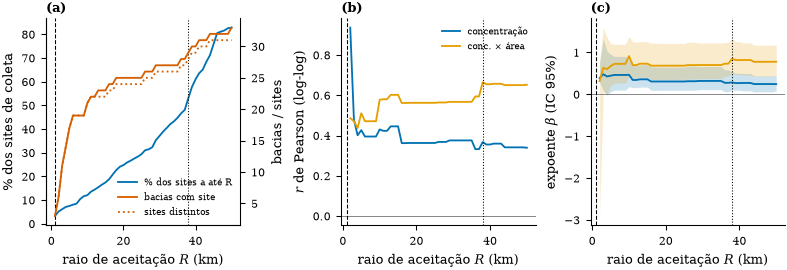

In [ ]:
R_GRADE = np.arange(1, R_MAX_KM + 1)
R_GARANTIDO = 1
chaves = [f"{k}_{s}" for s in ("conc", "qtd") for k in ("beta", "ic95_inf", "ic95_sup", "r", "p")]
linhas = []
for R in R_GRADE:
    dd = df_bacias[(df_bacias["dist_km"] <= R) & (df_bacias["pop_total"] > 0) & (df_bacias[COL_LIXO] > 0)]
    lin = dict.fromkeys(chaves, np.nan)
    lin.update(R_km=int(R), frac_sites=float((site["dist_sink_km"] <= R).mean()),
               n_bacias=len(dd), n_sites_distintos=int(dd["site_idx"].nunique()))
    for col, suf in ((COL_LIXO, "conc"), (COL_QTD, "qtd")):
        if len(dd) >= 5 and dd[col].nunique() >= 3:
            f = ajuste_escala(dd["pop_total"].to_numpy(), dd[col].to_numpy(), n_boot=2000)
            lin.update({f"beta_{suf}": f["beta"], f"ic95_inf_{suf}": f["ic95_inf"],
                        f"ic95_sup_{suf}": f["ic95_sup"], f"r_{suf}": f["r"], f"p_{suf}": f["p_r"]})
    linhas.append(lin)
varredura = pd.DataFrame(linhas)
varredura.to_csv(f"results/varredura_raio_{TAG}.csv", index=False)

acima = varredura.loc[varredura["frac_sites"] >= 0.5, "R_km"]
if len(acima):
    R_MAIORIA = int(acima.iloc[0])
else:
    R_MAIORIA = int(R_MAX_KM)
    print(f"ATENÇÃO: nem a {R_MAX_KM} km a maioria dos sites está perto de uma foz principal; usando R = {R_MAX_KM} km")
print(f"R_maioria = {R_MAIORIA} km ({varredura.loc[R_MAIORIA - 1, 'frac_sites']:.0%} dos sites)")
print(varredura.loc[varredura["R_km"].isin([1, 2, 5, 10, 20, 30, 40, 50, R_MAIORIA]),
                    ["R_km", "frac_sites", "n_bacias", "n_sites_distintos", "beta_conc", "r_conc", "p_conc",
                     "beta_qtd", "r_qtd"]].drop_duplicates().round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5), constrained_layout=True)
ax = axes[0]
ax.plot(varredura["R_km"], 100 * varredura["frac_sites"], c=OKABE[4], label="% dos sites a até R")
ax.set_ylabel("% dos sites de coleta")
ax2 = ax.twinx()
ax2.spines["right"].set_visible(True)
ax2.plot(varredura["R_km"], varredura["n_bacias"], c=OKABE[5], label="bacias com site")
ax2.plot(varredura["R_km"], varredura["n_sites_distintos"], c=OKABE[5], ls=":", label="sites distintos")
ax2.set_ylabel("bacias / sites")
ax.legend(handles=ax.get_lines() + ax2.get_lines(), loc="lower right", fontsize=6)
for suf, cor, rot in (("conc", OKABE[4], "concentração"), ("qtd", OKABE[0], "conc. × área")):
    axes[1].plot(varredura["R_km"], varredura[f"r_{suf}"], c=cor, label=rot)
    axes[2].fill_between(varredura["R_km"], varredura[f"ic95_inf_{suf}"], varredura[f"ic95_sup_{suf}"],
                         color=cor, alpha=0.2, lw=0)
    axes[2].plot(varredura["R_km"], varredura[f"beta_{suf}"], c=cor, label=rot)
axes[1].axhline(0, c="0.5", lw=0.6)
axes[1].set_ylabel("$r$ de Pearson (log-log)")
axes[2].axhline(0, c="0.5", lw=0.6)
axes[2].set_ylabel(r"expoente $\beta$ (IC 95%)")
axes[1].legend(fontsize=6)
for ax, l in zip(axes, "abc"):
    for R, ls in ((R_GARANTIDO, "--"), (R_MAIORIA, ":")):
        ax.axvline(R, c="k", lw=0.7, ls=ls)
    ax.set_xlabel("raio de aceitação $R$ (km)")
    letra(ax, l)
salva(fig, f"varredura_raio_{TAG}")
plt.show()

## 9. Mapas

Bacias principais (IPBA), manchas urbanas (CCA), sites de coleta e a foz de cada bacia principal. As fozes
com site a até $R_{\text{maioria}}$ ficam destacadas.

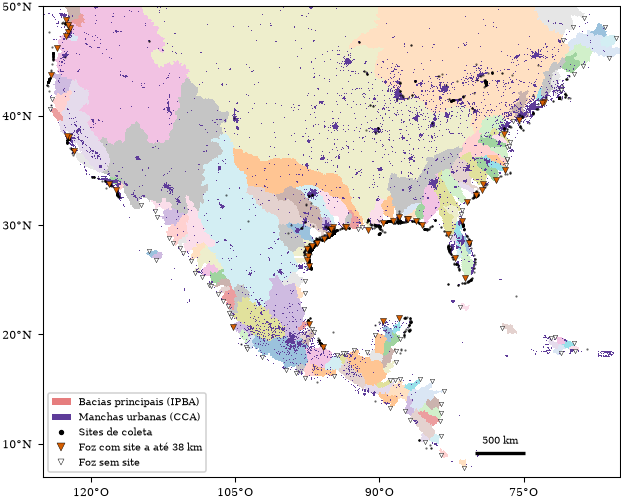

In [ ]:
com_site = df_bacias["dist_km"] <= R_MAIORIA
fig, ax = plt.subplots(figsize=(7.2, 4.6), constrained_layout=True)
camada_bacias(ax, alpha=0.45)
camada_manchas(ax)
ax.scatter(site["lon"], site["lat"], s=2, c="k", lw=0, alpha=0.6, zorder=4)
ax.scatter(df_bacias.loc[~com_site, "sink_lon"], df_bacias.loc[~com_site, "sink_lat"], s=8, marker="v",
           c="w", edgecolors="k", linewidths=0.3, zorder=5)
ax.scatter(df_bacias.loc[com_site, "sink_lon"], df_bacias.loc[com_site, "sink_lat"], s=16, marker="v",
           c=OKABE[5], edgecolors="k", linewidths=0.3, zorder=6)
ax.legend(handles=[Patch(fc=plt.cm.tab20(0.3), alpha=0.6, label="Bacias principais (IPBA)"),
                   Patch(fc=COR_MANCHA, label="Manchas urbanas (CCA)"),
                   Line2D([], [], ls="", marker="o", ms=2.5, c="k", label="Sites de coleta"),
                   Line2D([], [], ls="", marker="v", ms=5, mfc=OKABE[5], mec="k", mew=0.3,
                          label=f"Foz com site a até {R_MAIORIA} km"),
                   Line2D([], [], ls="", marker="v", ms=4, mfc="w", mec="k", mew=0.3, label="Foz sem site")],
          loc="lower left", fontsize=6.3, frameon=True, framealpha=0.9)
eixos_geo(ax, BOX)
barra_escala(ax, ESCALA_KM, pos=(0.75, 0.05))
salva(fig, f"mapa_integrado_{TAG}")
plt.show()

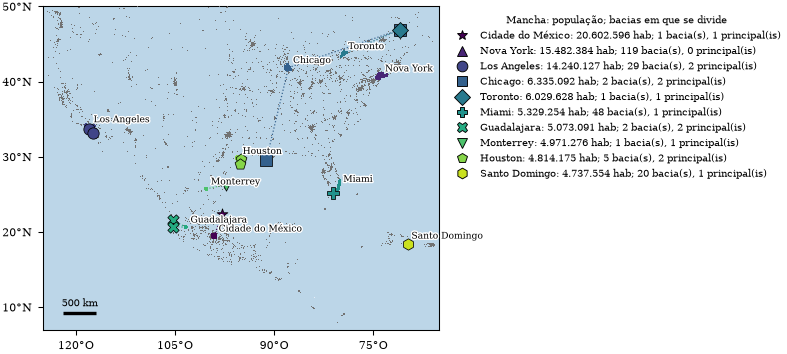

In [ ]:
# As N maiores manchas recebem cor própria, o nome no centroide e um símbolo na foz de cada bacia principal
# que recebe um pedaço delas (seção 6), ligado ao centroide por uma linha; as demais manchas ficam em cinza.
# Numa escala continental até uma mancha de 20 milhões de habitantes ocupa poucos pixels, por isso só na
# exibição as N maiores são dilatadas em DILATA_VIS blocos para cada lado.
DILATA_VIS = 2
N_TOP = min(10, n_cidades)
marcadores = ["*", "^", "o", "s", "D", "P", "X", "v", "p", "h"]
top_ids = np.argsort(pop_cidades)[::-1][:N_TOP] + 1
cores = plt.cm.viridis(np.linspace(0, 0.92, N_TOP))

# nível N_TOP para a maior mancha, 1 para a décima e 0 para as outras: no máximo em blocos a maior prevalece
lut = np.full(n_cidades + 1, 0, dtype=np.int16)
lut[0] = -1
lut[top_ids] = np.arange(N_TOP, 0, -1)
niveis = blocos(lut[cidades], FATOR_VIS, np.max).astype(float)
destaque = ndi.grey_dilation(np.where(niveis > 0, niveis, 0), size=2 * DILATA_VIS + 1)
niveis = np.where(destaque > 0, destaque, niveis)
niveis[niveis < 0] = np.nan
centros = np.array(ndi.center_of_mass(dens, cidades, index=top_ids))
lon_c = np.interp(centros[:, 1], np.arange(pop.sizes["x"]), pop.x.values)
lat_c = np.interp(centros[:, 0], np.arange(pop.sizes["y"]), pop.y.values)

fig, ax = plt.subplots(figsize=(7.2, 4.4), constrained_layout=True)
camada_bacias(ax, alpha=0.3)
ax.imshow(niveis, extent=extensao_blocos(pop, FATOR_VIS),
          cmap=ListedColormap(["0.45", *cores[::-1]]), vmin=-0.5, vmax=N_TOP + 0.5, zorder=3)

alcas = []
for cid, cor, mk, lo, la in zip(top_ids, cores, marcadores, lon_c, lat_c):
    p = pedacos[pedacos["mancha"].eq(cid) & pedacos["bacia_principal"]]
    for b in p["basin_id"]:
        ax.plot([lo, sink_pos[b][0]], [la, sink_pos[b][1]], c=cor, lw=0.8, ls=":", zorder=5)
        ax.scatter(*sink_pos[b], s=55, marker=mk, color=cor, edgecolors="k", linewidths=0.5, zorder=6)
    nome = nomes.get(cid, f"Mancha {cid}")
    ax.annotate(nome, (lo, la), xytext=(3, 3), textcoords="offset points", fontsize=6, zorder=7,
                path_effects=[pe.withStroke(linewidth=1.8, foreground="w")])
    n_div = int((pedacos["mancha"].eq(cid) & pedacos["basin_id"].gt(0)).sum())
    alcas.append(Line2D([], [], ls="", marker=mk, ms=7, mfc=cor, mec="k", mew=0.6,
                        label=f"{nome}: {fmt_br(pop_cidades[cid - 1])} hab; {n_div} bacia(s), {len(p)} principal(is)"))
ax.legend(handles=alcas, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=6.5,
          title="Mancha: população; bacias em que se divide", title_fontsize=6.5)
eixos_geo(ax, BOX)
barra_escala(ax, ESCALA_KM)
salva(fig, f"mapa_manchas_fozes_{TAG}")
plt.show()

## 10. Alometria por bacia: população × lixo

Cada ponto é uma bacia principal. Eixo x: população residente na bacia (GPW v4, com as manchas divididas
pela cumeada, seção 6). Eixo y: lixo da bacia pelo site mais próximo da foz, como concentração (esquerda) e
como concentração × área (direita). Linha de cima: só as bacias com **medição garantida** (site a até 1 km
da foz). Linha de baixo: bacias com site a até $R_{\text{maioria}}$.

Ajuste da lei de escala $y = c\,x^{\beta}$ por mínimos quadrados em $\log_{10}$: $\beta = 0$ é ausência de
relação, $\beta = 1$ é proporcionalidade (lixo por habitante constante), $\beta < 1$ é sublinear e $\beta > 1$
superlinear (Bettencourt et al., 2007). A faixa cinza é o IC de 95% por bootstrap de pares (10.000
reamostragens) e $p_\mathrm{perm}$ testa $\beta = 0$ por permutação. Bacias vizinhas continuam
espacialmente correlacionadas (compartilham correntes e fontes), então com $n$ pequeno o $p$ é descritivo.
No painel de concentração × área, a área também está embutida na população (bacias grandes tendem a ter
mais gente), o que puxa $\beta$ para cima por construção.

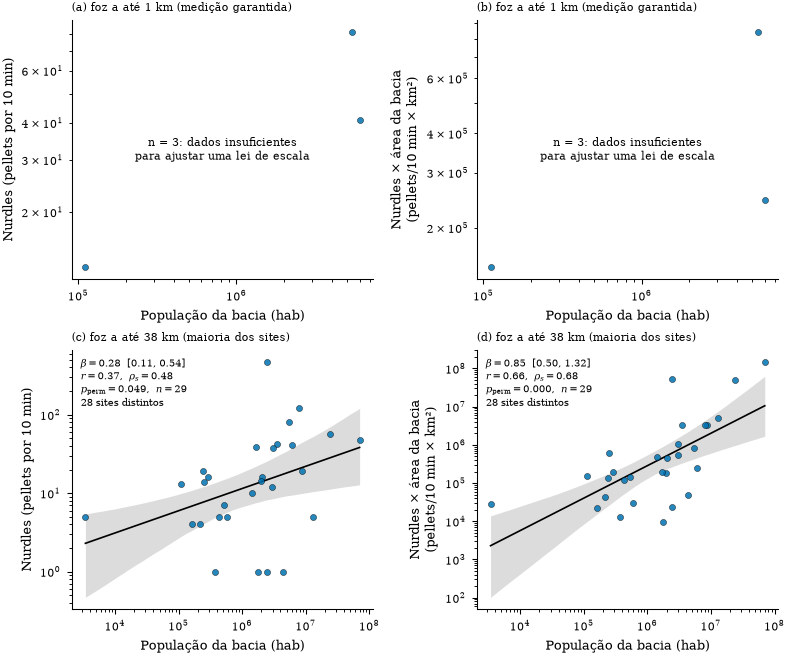

                            n   beta  log10_c  ic95_inf  ic95_sup  p_perm      r   p_r    rho  p_rho     r2  n_sites_distintos
R=38km | nurdles_10min   29.0  0.283   -0.641     0.108     0.539   0.049  0.367  0.05  0.480  0.008  0.135               28.0
R=38km | nurdles_x_area  29.0  0.849    0.360     0.503     1.321   0.000  0.665  0.00  0.684  0.000  0.442               28.0
Salvos: results/bacias_na_panama.csv, results/manchas_por_bacia_na_panama.csv, results/escala_pop_lixo_na_panama.csv e results/varredura_raio_na_panama.csv


In [ ]:
CONJUNTOS = [(R_GARANTIDO, f"foz a até {R_GARANTIDO} km (medição garantida)"),
             (R_MAIORIA, f"foz a até {R_MAIORIA} km (maioria dos sites)")]
VARIAVEIS = [(COL_LIXO, ROTULO_LIXO), (COL_QTD, ROTULO_QTD)]
ajustes = {}
fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.0), constrained_layout=True)
for i, (R, nome_R) in enumerate(CONJUNTOS):
    for k, (col, rot) in enumerate(VARIAVEIS):
        ax = axes[i, k]
        dd = df_bacias[(df_bacias["dist_km"] <= R) & (df_bacias["pop_total"] > 0) & (df_bacias[col] > 0)]
        ax.set(xscale="log", yscale="log")
        ax.scatter(dd["pop_total"], dd[col], s=16, c=OKABE[4], edgecolors="k", linewidths=0.3, alpha=0.85, zorder=3)
        if len(dd) >= 5 and dd[col].nunique() >= 3:
            f = ajuste_escala(dd["pop_total"].to_numpy(), dd[col].to_numpy())
            f["n_sites_distintos"] = int(dd["site_idx"].nunique())
            ajustes[f"R={R}km | {col}"] = f
            ax.fill_between(10 ** f["xs"], 10 ** f["banda"][0], 10 ** f["banda"][1], color="0.7", alpha=0.45, lw=0)
            ax.plot(10 ** f["xs"], 10 ** f["ys"], c="k", lw=1.1)
            ax.text(0.03, 0.97, texto_ajuste(f) + f"\n{f['n_sites_distintos']} sites distintos",
                    transform=ax.transAxes, va="top", fontsize=6.5)
        else:
            ax.text(0.5, 0.5, f"n = {len(dd)}: dados insuficientes\npara ajustar uma lei de escala",
                    transform=ax.transAxes, ha="center", va="center", fontsize=7)
        ax.set_title(f"({'abcd'[2 * i + k]}) {nome_R}", loc="left", fontsize=7.5)
        ax.set_xlabel("População da bacia (hab)")
        ax.set_ylabel(rot)
salva(fig, f"dispersao_pop_lixo_{TAG}")
plt.show()

tabela_escala = pd.DataFrame({k: {c: v for c, v in f.items() if c not in ("xs", "ys", "banda")}
                              for k, f in ajustes.items()}).T
print(tabela_escala.round(3).to_string())
tabela_escala.to_csv(f"results/escala_pop_lixo_{TAG}.csv")
df_bacias.to_csv(f"results/bacias_{TAG}.csv", index=False)
pedacos.to_csv(f"results/manchas_por_bacia_{TAG}.csv", index=False)
print(f"Salvos: results/bacias_{TAG}.csv, results/manchas_por_bacia_{TAG}.csv, "
      f"results/escala_pop_lixo_{TAG}.csv e results/varredura_raio_{TAG}.csv")

## 11. A correlação depende de poucas bacias?

Teste *leave-one-out* no conjunto de $R_{\text{maioria}}$ (concentração): recalcula $r$ e $\beta$ removendo uma
bacia por vez. O critério de robustez é o quanto $r$ muda, não se o $p$ cruza 0,05. Se nenhuma remoção
desloca $r$ em mais de ~0,1 (faixa cinza), nenhuma bacia isolada controla o resultado.

com todas as 29 bacias: r = 0.367, β = 0.283
leave-one-out: r de 0.332 a 0.430; β de 0.252 a 0.353
 basin_id    pop_total  r_sem  beta_sem  delta_r
     4146 4.350719e+06 0.4297    0.3158   0.0623
     3284 2.477333e+06 0.4087    0.2990   0.0414
     1136 1.285983e+07 0.4059    0.3188   0.0385
     5937 2.423901e+07 0.3322    0.2621  -0.0352
     4479 7.020225e+07 0.3323    0.2740  -0.0351


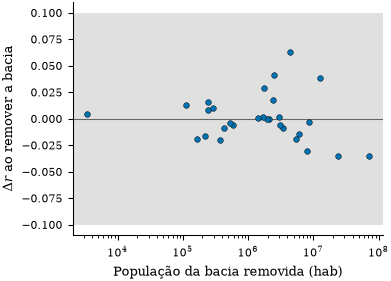

=> nenhuma bacia isolada desloca r em mais de 0,1


In [ ]:
d = df_bacias[(df_bacias["dist_km"] <= R_MAIORIA) & (df_bacias["pop_total"] > 0) & (df_bacias[COL_LIXO] > 0)]
if len(d) < 5:
    print(f"só {len(d)} bacias a até {R_MAIORIA} km: leave-one-out não se aplica")
else:
    lx, ly = np.log10(d["pop_total"].to_numpy()), np.log10(d[COL_LIXO].to_numpy())
    r = pearsonr(lx, ly)[0]
    beta_todas = np.polyfit(lx, ly, 1)[0]
    loo = pd.DataFrame([{"basin_id": b, "pop_total": pt,
                         "r_sem": pearsonr(np.delete(lx, i), np.delete(ly, i))[0],
                         "beta_sem": np.polyfit(np.delete(lx, i), np.delete(ly, i), 1)[0]}
                        for i, (b, pt) in enumerate(zip(d["basin_id"], d["pop_total"]))])
    loo["delta_r"] = loo["r_sem"] - r

    print(f"com todas as {len(d)} bacias: r = {r:.3f}, β = {beta_todas:.3f}")
    print(f"leave-one-out: r de {loo['r_sem'].min():.3f} a {loo['r_sem'].max():.3f}; "
          f"β de {loo['beta_sem'].min():.3f} a {loo['beta_sem'].max():.3f}")
    print(loo.reindex(loo["delta_r"].abs().sort_values(ascending=False).index).head(5).round(4).to_string(index=False))

    fig, ax = plt.subplots(figsize=(3.6, 2.6), constrained_layout=True)
    ax.axhspan(-0.1, 0.1, color="0.88", lw=0, zorder=0)
    ax.axhline(0, c="0.4", lw=0.7)
    ax.scatter(loo["pop_total"], loo["delta_r"], s=14, c=OKABE[4], edgecolors="k", linewidths=0.3, zorder=3)
    ax.set(xscale="log", xlabel="População da bacia removida (hab)", ylabel=r"$\Delta r$ ao remover a bacia")
    salva(fig, f"leave_one_out_{TAG}")
    plt.show()

    maior = loo["delta_r"].abs().max()
    print("=> nenhuma bacia isolada desloca r em mais de 0,1" if maior < 0.1 else
          f"=> uma única bacia desloca r em {maior:.2f}: o resultado é sensível a pontos influentes")

## 12. Leis de potência nas distribuições

Três variáveis do pipeline costumam ter cauda pesada:

* **área das bacias de drenagem** — em redes fluviais, $P(A > a) \sim a^{-(\tau - 1)}$ com $\tau \approx 1{,}4$–$1{,}5$ (Rodríguez-Iturbe & Rinaldo, 1997), e a percolação invasiva que o IPBA implementa também gera bacias de tamanho livre de escala;
* **população por bacia** (todas as bacias do recorte, não só as principais);
* **população das manchas urbanas** do CCA (lei de Zipf; a análise nacional está em `01_Zipf_calibracao_CCA.ipynb`).

Para cada uma: ajuste de Clauset, Shalizi & Newman (2009) pelo pacote `powerlaw` (Alstott et al., 2014) — expoente $\gamma$ de $p(x) \propto x^{-\gamma}$ por máxima verossimilhança, com $x_{\min}$ escolhido minimizando a distância KS — e teste da razão de log-verossimilhança $R$ contra a lognormal e a exponencial. $R > 0$ favorece a lei de potência, mas o teste só decide se $p < 0{,}1$; caso contrário os dois modelos são indistinguíveis com estes dados. As bacias que tocam a borda do recorte ficam de fora da distribuição de área porque estão truncadas.

Um recorte regional tem cauda curta: "indistinguível da lognormal" aqui não é evidência a favor da lei de potência, é falta de poder estatístico.

                                         n       xmin n_cauda gamma erro_gamma    KS R_lognormal p_lognormal R_exponencial p_exponencial    vs_lognormal   vs_exponencial
Área das bacias (km²)                11794     81.939    1877 1.655      0.015 0.022      -1.204       0.229         8.194         0.000  indistinguível  lei de potência
População das bacias (hab)           11134 86,141.626     482 1.795      0.036 0.021      -0.537       0.591         5.927         0.000  indistinguível  lei de potência
População das manchas urbanas (hab)  12185  7,300.788    2939 1.782      0.014 0.018      -1.763       0.078        10.994         0.000     alternativa  lei de potência


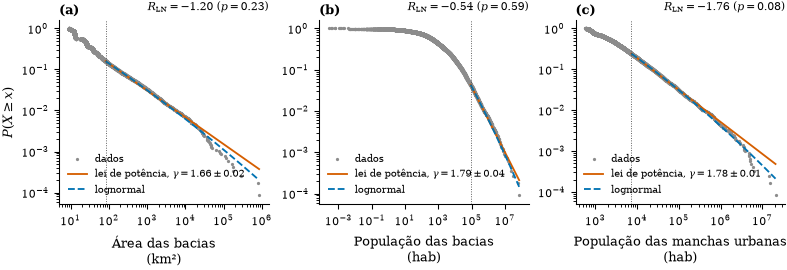

In [ ]:
import warnings
from scipy.stats import lognorm


def ajusta_cauda(x):
    x = np.asarray(x, dtype=float)
    x = x[x > 0]
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        fit = powerlaw.Fit(x, verbose=False)
        R_ln, p_ln = fit.distribution_compare("power_law", "lognormal", normalized_ratio=True)
        R_ex, p_ex = fit.distribution_compare("power_law", "exponential", normalized_ratio=True)
    return fit, dict(n=len(x), xmin=fit.xmin, n_cauda=int(np.sum(x >= fit.xmin)),
                     gamma=fit.power_law.alpha, erro_gamma=fit.power_law.sigma, KS=fit.power_law.D,
                     R_lognormal=R_ln, p_lognormal=p_ln, R_exponencial=R_ex, p_exponencial=p_ex)


def veredito(R, p):
    if p >= 0.1:
        return "indistinguível"
    return "lei de potência" if R > 0 else "alternativa"


pop_todas = ndi.sum(dens, bac_pop, index=ids)
series = {"Área das bacias (km²)": df_areas.loc[~df_areas["toca_borda"], "area_km2"].to_numpy(),
          "População das bacias (hab)": pop_todas[pop_todas > 0],
          "População das manchas urbanas (hab)": pop_cidades[pop_cidades > 0]}

resumo, fits = {}, {}
for nome, x in series.items():
    if len(x) < 50:
        print(f"{nome}: só {len(x)} valores, insuficiente para ajustar a cauda")
        continue
    fits[nome], resumo[nome] = ajusta_cauda(x)
    s = resumo[nome]
    s["vs_lognormal"] = veredito(s["R_lognormal"], s["p_lognormal"])
    s["vs_exponencial"] = veredito(s["R_exponencial"], s["p_exponencial"])

tabela_cauda = pd.DataFrame(resumo).T
print(tabela_cauda.to_string(float_format=lambda v: f"{v:,.3f}"))
tabela_cauda.to_csv(f"results/leis_potencia_{TAG}.csv")

fig, axes = plt.subplots(1, len(fits), figsize=(7.2, 2.5), constrained_layout=True, squeeze=False)
for ax, (nome, fit), l in zip(axes[0], fits.items(), "abc"):
    x = np.sort(series[nome][series[nome] > 0])
    n, s = len(x), resumo[nome]
    ax.loglog(x, 1.0 - np.arange(n) / n, ".", ms=2.2, c="0.55", label="dados", rasterized=True)
    xs = np.logspace(np.log10(fit.xmin), np.log10(x.max()), 120)
    frac_cauda = s["n_cauda"] / n
    ax.loglog(xs, frac_cauda * (xs / fit.xmin) ** (1.0 - s["gamma"]), c=OKABE[5],
              label=f"lei de potência, $\\gamma = {s['gamma']:.2f} \\pm {s['erro_gamma']:.2f}$")
    ln = lognorm(s=fit.lognormal.sigma, scale=np.exp(fit.lognormal.mu))
    ax.loglog(xs, frac_cauda * ln.sf(xs) / ln.sf(fit.xmin), "--", c=OKABE[4], label="lognormal")
    ax.axvline(fit.xmin, c="0.3", lw=0.6, ls=":")
    ax.set_xlabel(nome.replace(" (", "\n("))
    ax.set_title(f"$R_\\mathrm{{LN}} = {s['R_lognormal']:.2f}$ ($p = {s['p_lognormal']:.2f}$)",
                 loc="right", fontsize=7)
    ax.legend(loc="lower left", fontsize=6.3)
    letra(ax, l)
axes[0][0].set_ylabel(r"$P(X \geq x)$")
salva(fig, f"leis_potencia_{TAG}")
plt.show()